### Simple environment
using random jamming, single action instead of dual for simplicity (1 action , identified by freq * power)


In [1]:
import gymnasium as gym
import numpy as np
import random as random
from gymnasium import spaces
from gymnasium.envs.registration import register     #name the env
from gymnasium.utils.env_checker import check_env   #check if the env follows the gym API   
import matplotlib.pyplot as plt
from IPython.display import display
import time

#make the name of the env
register(
    id='AntiJammingEnv-v0',                         #name of the env when we instatiate
    # entry_point="simplenv.ipynb:AntiJammingEnv",   #module name:class name
    entry_point= lambda **kwargs: AntiJammingEnv(**kwargs),  #if the class is in the same file, we can use lambda
)


class AntiJammingEnv(gym.Env):
    # used to render the env
    metadata = {"render_modes": ["human"], "render_fps": 4}


    def __init__(self, num_freqs=22, num_powers=50, num_of_jammers=7, jammer_type="sweeping", render_mode=None):
        super().__init__()
        self.num_freqs = num_freqs
        self.num_powers = num_powers
        self.jammer_type = jammer_type          #random in this env
        self.num_of_jammers = num_of_jammers    # 7 random jammers
        self.prev_freq = None                   #need for freq switching penalty
        self.state = None                 # current observation (PSD vector)
        self._sweep_step = 1             # how many bins to move per step for sweeping jammer
        self.power_levels = np.linspace(1.58e-4, 1e-3, num_powers)  # power levels from -8dbm to 0dbm converted to watts , taken from the paper (50 levels)
        self.jammer_power = 3.162e-3 # Jammer power 3.162e-3 W = 5 dBm from Table 1 in the paper
        #all rendering related variables
        self.render_mode = render_mode
        self._fig = None
        self._ax = None
        self._jam_bars = None
        self._agent_line = None
        self._power_text = None
        self._last_action = None
        self._last_reward = None
        self._total_reward = 0.0
        self.agent_marker = None
        self._display_handle = None


        # Define action space (freq × power combinations)
        # 22 * 50 = 1100 discrete actions (0..1099)
        # too many actions for DQN, but OK for policy gradient methods
        self.action_space = spaces.Discrete(num_freqs * num_powers)

        # State = PSD (vector of size num_freqs)
        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(num_freqs,), dtype=np.float32
        )

        #self.rng = random number generator
        self.rng = np.random.default_rng()

        # Internal jammer state & dynamics parameters
        self._jam_idxs = []             # indices of the currently jammed frequency bins


    def _build_state_from_jammer(self):
        """
        Construct the PSD observation vector given the *current* jammers indecies.
        - Background noise is simulated as small random values (0..0.1).
        - Multiple freqs (self._jam_idxs) is set to 1.0 to represent the jammer’s power.
        
        This function is used in both `reset()` and `step()` so that
        the observation is always generated consistently.
        """
        s = self.rng.random(self.num_freqs) * 0.1   # background noise
        if len(self._jam_idxs) == 0:                   # if no jammer index yet, pick a random one
            self._jam_idxs = self.np_random.choice(range(self.num_freqs), size=self.num_of_jammers, replace=False).tolist()
        for i in self._jam_idxs:
            s[i] = 1.0
    
        return s.astype(np.float32)
    
    

    def _advance_jammer(self):
        """
        Update the jammer index based on jammer_type dynamics:
        - fixed: jammer never moves
        - sweeping: jammer shifts to the next bin each step
        - random: jammer picks a new random bin every step
        """

        jt = self.jammer_type.lower()
        if jt == "fixed":
            pass  # jammer stays in the same bin forever

        elif jt == "sweeping":
            for i in range(len(self._jam_idxs)):
                #modulo to wrap around (23 -> 1 for example)
                self._jam_idxs[i] = (self._jam_idxs[i] + self._sweep_step) % self.num_freqs

        else:  # default "random"
            for i in range(len(self._jam_idxs)):
                self._jam_idxs[i] = int(self.rng.integers(0, self.num_freqs))



    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        # Initialize jammer index and build the first observation
        # used self.np_random that apparently got initted by super().reset(seed=seed)
        self._jam_idxs = self.np_random.choice(self.num_freqs, size=self.num_of_jammers, replace=False).tolist()
        self.state = self._build_state_from_jammer()

        self.prev_freq = None
        info = {}

        #rendering related book-keeping
        self._last_state = self.state      # so first render works
        self._last_action = None
        self._last_reward = None

        return self.state.astype(np.float32), info
    



    def step(self, action):

        """
        One-slot delay logic:
        - Agent picked `action` using observation s_k (= self._last_state).
        - Environment first advances jammer to unseen slot k+1 and measures s_{k+1}.
        - Reward is computed against s_{k+1} (the actual slot you just transmitted in).
        - Next observation returned to agent is s_{k+1}.
        """
        # Decode (freq, power)
        freq = action // self.num_powers
        power = action % self.num_powers + 1  # 1..num_powers
        alpha_k_user   = 9.1e-12    # from SNR_clean target (≈12 dB)
        alpha_k_jammer = 1.15e-12   # from desired jammed SINR (≈0 dB)
        gain_vector_user = alpha_k_user * -1*np.log(self.rng.random(22))  # channel gain vector for all frequencies sampled each step 
        gain_vector_jammer = alpha_k_jammer * -1*np.log(self.rng.random(22))  # channel gain vector for all frequencies sampled each step
        # Map integer range [1, 50] to actual wattage range defined above. its correct
        power = self.power_levels[power - 1]  
       

        # === Move to *new* (unseen) slot and measure PSD_{k+1} ===
        #uncomment this 2 lines for 1slot delay
        self._advance_jammer()
        curr_psd = self._build_state_from_jammer()    # s_{k+1}

        #uncomment this line for 0slot delay
        # curr_psd = self.state  # s_{k}

        # --- Compute reward using the *current* slot conditions (which were not observed before acting) ---
        noise_at_chosen = curr_psd[freq]
        powerNoise = 3.162e-16 # on equation (noise= kTNF) , 3.162e-16 = kTN for T=290K and (W = 25kHZ and converted to dBm 10log10(W)) and NF = 5dBm as a modest Reciever.
        jamming_power = self.jammer_power*gain_vector_jammer[freq] if noise_at_chosen > 0.9 else 0 # if jammer is present, its power is 3.162e-3 W (5 dBm) * gain of jammer as in the paper, else very small power 1e-10 W
        sinr = (power*gain_vector_user[freq]) / (powerNoise+jamming_power)

        #crc calculation
        beta_th = 10**(8/10)  # SINR threshold for successful CRC, it is taken from GPT as a standard practice with QPSK modulation, but can be manipulated between 6-10 dbm , this shows 8dbm
        crc_success = 1 if sinr > beta_th else 0

        # Switching penalty (compare with last used freq)   
        switching_penalty = 0.0
        if self.prev_freq is not None and self.prev_freq != freq:
            switching_penalty = 1.0
        
    
        subBandWidth = 25e3 # 25 kHz , taking from the paper that the base is 20 kHz and some roll-off margin
        epsilon = 1.5e8 # taken from GPT, suggested to make the affect of the power in the same scale with swithcing and etc.. 
        alpha = 0.5 # weight for switching penalty from the paper Table 1
        #reward = crc_success * (np.log(1 + snr_for_reward) / power) - penalty
        reward = (crc_success * (((subBandWidth * np.log2(1+sinr))/(epsilon*power))))-(alpha*switching_penalty)
#             print(
#     f"\n[Step Debug]"
#     f"\nFreq: {freq} | Power (W): {power:.3e} | PSD@Freq: {noise_at_chosen:.2f} "
#     f"| Jammed: {noise_at_chosen>0.9}"
#     f"\nUserGain: {gain_vector_user[freq]:.3e} | JammerGain: {gain_vector_jammer[freq]:.3e}"
#     f"\nSINR: {sinr:.3e} | SINR_dB: {10*np.log10(sinr+1e-12):.2f} dB"
#     f"\nCRC: {crc_success} | SwitchPenalty: {switching_penalty}"
#     f"\nReward: {reward:.6f} | TotalReward: {self._total_reward + reward:.6f}"
# )

        # Update previous freq
        self.prev_freq = freq

        # === One-slot-delay book-keeping ===
        # Next observation is the PSD we just measured in this slot.
        
        #uncomment this for 1slot delay
        self._last_state = curr_psd      # used for rendering
        self.state = curr_psd

        #uncomment this for 0slot delay
        # self._advance_jammer()
        # next_state = self._build_state_from_jammer()   # s_{k+1}
        # self.state = next_state

        terminated = False
        truncated = False
        info = {}

        #rendering related book-keeping
        self._last_action = (freq, power)
        self._last_reward = float(reward)
        self._total_reward = self._total_reward + reward
        if self.render_mode == "human":
            self.render()
        
        return self.state.astype(np.float32), reward, terminated, truncated, info


    def render(self):
        if self.render_mode != "human":
            return

        # ── show the PSD from the slot where the last action was used ────────────
        psd_to_show = self._last_state if getattr(self, "_last_state", None) is not None else self.state
        # ─────────────────────────────────────────────────────────────────────────

        # Lazily build the figure once
        if self._fig is None or not plt.fignum_exists(self._fig.number):
            plt.ioff()
            self._fig, self._ax = plt.subplots(figsize=(10, 4))
            self._ax.set_title("Anti-jamming spectrum (live)")
            self._ax.set_xlabel("Frequency bin")
            self._ax.set_ylabel("PSD / jammer power")
            self._ax.set_ylim(0.0, 1.2)
            self._ax.set_xlim(-0.5, self.num_freqs - 0.5)

            self._jam_bars = self._ax.bar(
                range(self.num_freqs),
                psd_to_show if psd_to_show is not None else np.zeros(self.num_freqs),
                color="#1f77b4",
                alpha=0.75,
            )
            self._agent_marker = self._ax.scatter(
                [], [], s=120, color="#ff7f0e", edgecolor="black", zorder=5
            )
            self._power_text = self._ax.text(
                0.01, 0.97, "Awaiting first action",
                transform=self._ax.transAxes,
                fontsize=11, va="top",
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
            )
            self._fig.canvas.draw()
            self._display_handle = display(self._fig, display_id=True)

        # ── update jammer bars ────────────────────────────────────────────────────
        if psd_to_show is not None:
            for bar, height in zip(self._jam_bars, psd_to_show):
                bar.set_height(height)
                bar.set_color("#d62728" if height > 0.9 else "#1f77b4")

        # ── update agent marker & annotation ──────────────────────────────────────
        if self._last_action is not None:
            freq, power_w = self._last_action
            self._agent_marker.set_offsets([[freq, psd_to_show[freq]]])

            lines = [
                f"Agent freq = {freq}",
                f"Power = {power_w:.2e} W",
            ]
            if self._last_reward is not None:
                lines.append(f"Reward = {self._last_reward:.3f}")
            if self._total_reward is not None:
                lines.append(f"Total = {self._total_reward:.3f}")

            self._power_text.set_text("\n".join(lines))
        else:
            self._agent_marker.set_offsets([])
            self._power_text.set_text("Awaiting first action")

        # ── draw & throttle frame rate ────────────────────────────────────────────
        self._fig.canvas.draw()
        if self._display_handle is not None:
            self._display_handle.update(self._fig)
            time.sleep(0.8)


### ONLY FOR PLOTTING THE REWARD FUNCTION FULLY ### 

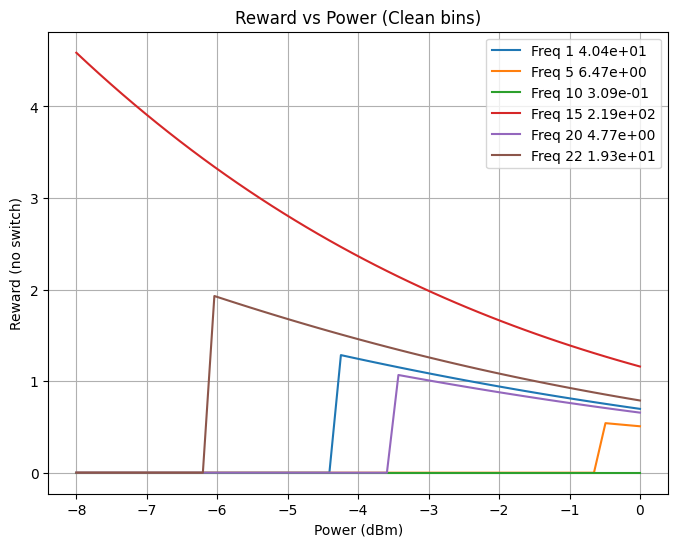

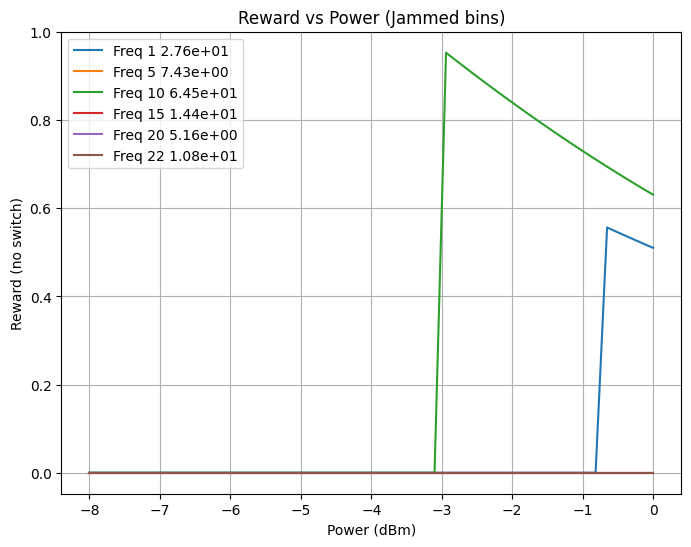

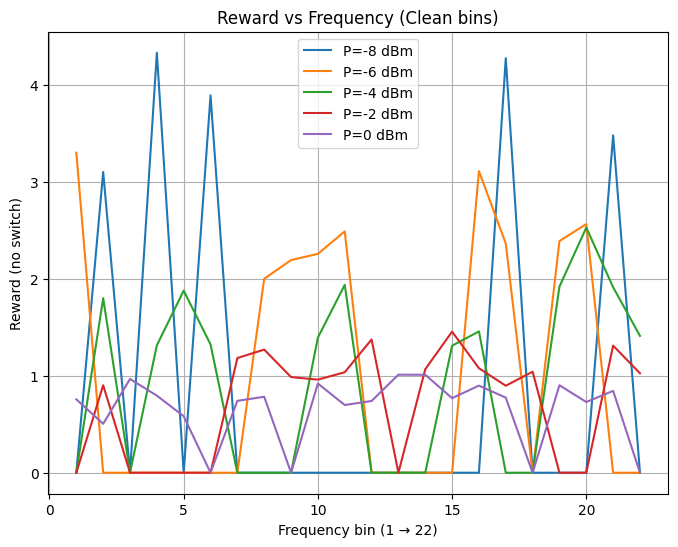

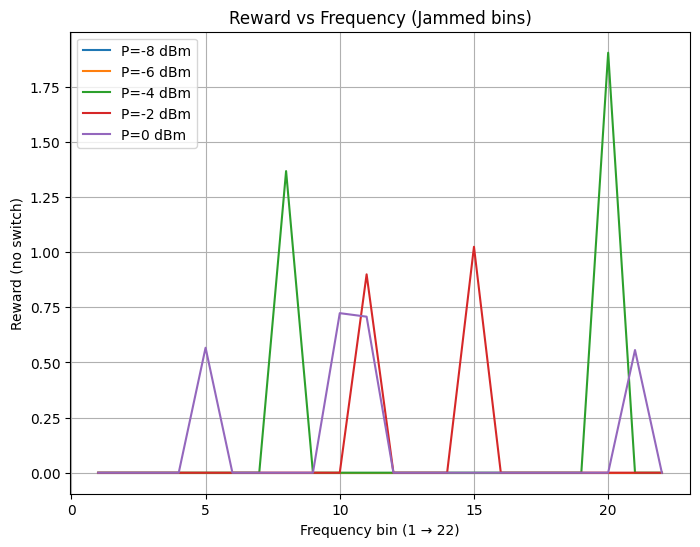

In [101]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Config (aligns with your env)
# =========================
B = 25e3                          # Hz (bandwidth)
epsilon = 1.5e8                   # energy scaling
beta_th = 10**(8/10)              # CRC threshold (8 dB, linear)
noise_power = 3.162e-16           # W (kTB * NF for 25 kHz, NF=5 dB)
jammer_power = 3.162e-3           # W (5 dBm)
alpha_k_user   = 9.1e-12          # mean user gain (calibrated)
alpha_k_jammer = 1.15e-12         # mean jammer gain (calibrated)

# Sweep ranges (ascending as requested)
freqs = np.arange(1, 23)                      # 1..22
powers_dbm = np.linspace(-8, 0, 50)           # dBm, ascending
powers_w = 1e-3 * 10**(powers_dbm / 10.0)     # W, ascending

rng = np.random.default_rng(123)

# =========================
# Reward definition (no switch penalty here to show the surface cleanly)
# r = phi * (B * log2(1 + SINR) / (epsilon * P))
# SINR = (P * g_user) / (noise_power + I_jam)
# =========================
def reward_single(power_w, jammed, g_user, g_jam):
    I_jam = jammer_power * g_jam if jammed else 0.0
    sinr = (power_w * g_user) / (noise_power + I_jam)
    phi = 1.0 if sinr > beta_th else 0.0
    throughput = B * np.log2(1.0 + sinr)
    return phi * (throughput / (epsilon * power_w))

def sample_gain_user():
    return rng.exponential(scale=alpha_k_user)

def sample_gain_jam():
    return rng.exponential(scale=alpha_k_jammer)

# =========================
# Plot 1: Reward vs Power (for multiple freqs) — clean and jammed
# =========================
def plot_reward_vs_power(selected_freqs=(1,5,10,15,20,22), jammed=False, title_suffix=""):
    plt.figure(figsize=(8, 6))
    for f in selected_freqs:
        # Fix gains per curve to avoid noisy wiggles across the sweep
        g_u = sample_gain_user()
        g_j = sample_gain_jam()
        rewards = [reward_single(pw, jammed, g_u, g_j) for pw in powers_w]
        plt.plot(powers_dbm, rewards, label=f"Freq {f} {(g_u/g_j):.2e}")
    plt.xlabel("Power (dBm)")                    # −8 → 0 (ascending)
    plt.ylabel("Reward (no switch)")
    plt.title(f"Reward vs Power {title_suffix}".strip())
    plt.grid(True)
    plt.legend()
    plt.show()

# =========================
# Plot 2: Reward vs Frequency (for multiple powers) — clean and jammed
# =========================
def plot_reward_vs_frequency(selected_p_dbm=(-8, -6, -4, -2, 0), jammed=False, title_suffix=""):
    plt.figure(figsize=(8, 6))
    for p_dbm in selected_p_dbm:
        p_w = 1e-3 * 10**(p_dbm / 10.0)
        # New gains per-frequency to reflect independent fading across bins
        rewards = []
        for _ in freqs:  # 1 → 22 (ascending)
            g_u = sample_gain_user()
            g_j = sample_gain_jam()
            rewards.append(reward_single(p_w, jammed, g_u, g_j))
        plt.plot(freqs, rewards, label=f"P={p_dbm} dBm")
    plt.xlabel("Frequency bin (1 → 22)")
    plt.ylabel("Reward (no switch)")
    plt.title(f"Reward vs Frequency {title_suffix}".strip())
    plt.grid(True)
    plt.legend()
    plt.show()

# =========================
# Usage examples (uncomment the ones you want)
# =========================
plot_reward_vs_power(jammed=False, title_suffix="(Clean bins)")
plot_reward_vs_power(jammed=True,  title_suffix="(Jammed bins)")
plot_reward_vs_frequency(jammed=False, title_suffix="(Clean bins)")
plot_reward_vs_frequency(jammed=True,  title_suffix="(Jammed bins)")


### Check random policy for a few episodes


In [102]:
import gymnasium as gym

num_episodes = 30
max_steps = 15
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action = env.action_space.sample()
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}") if (ep+1) % 5 == 0 else None
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()


Episode 5: return=1.89, steps=15
Episode 10: return=1.33, steps=15
Episode 15: return=3.49, steps=15
Episode 20: return=-2.46, steps=15
Episode 25: return=2.39, steps=15
Episode 30: return=0.53, steps=15
Mean reward over episodes: 2.97


## create a greedy policy (no RL in greedy, just to see if RL works)
decode action is a helper function to return freq and power from single action space of freq * power

In [10]:
def greedy_policy(obs, env, sinr_thresh_db: float = 8.0):
    """
    One-step optimal (delay-free) greedy policy:
      - looks at the current PSD observation `obs`
      - evaluates every (freq, power) pair with *exactly* the same
        reward calculation used in env.step()
      - returns the arg-max action index.

    Assumes env exposes:
        num_freqs, num_powers, power_levels (list of W),
        jammer_power, prev_freq (or None).
    The physical/constants mirror those in env.step().
    """
    obs = np.asarray(obs, dtype=np.float64)

    # --- constants identical to env.step() -----------------------------
    alpha_k_user   = 9.1e-12           # mean Rayleigh gain used in paper
    power_noise    = 3.162e-16         # kT·NF for 25 kHz, NF=5 dB
    sub_bandwidth  = 25e3              # 25 kHz
    epsilon        = 1.5e8             # paper’s scaling factor for rate term
    alpha_switch   = 0.5               # switching-penalty weight (Table I)
    beta_th        = 10 ** (sinr_thresh_db / 10.0)
    # -------------------------------------------------------------------

    best_reward  = -np.inf
    best_action  = 0
    prev_freq    = env.prev_freq 

    for f in range(env.num_freqs):
        # “Jammed” flag exactly as in env.step()
        is_jammed      = obs[f] > 0.9
        jamming_power  = env.jammer_power if is_jammed else 0.0

        switch_penalty = alpha_switch if (prev_freq is not None and prev_freq != f) else 0.0

        for p_idx, p_watt in enumerate(env.power_levels):
            # Use *expected* channel gain (alpha_k_user) – agent can’t see fast-fading
            sinr         = (p_watt * alpha_k_user) / (power_noise + jamming_power)
            crc_success  = int(sinr > beta_th)

            reward = crc_success * (sub_bandwidth * np.log2(1.0 + sinr)) / (epsilon * p_watt) - switch_penalty

            if reward > best_reward:
                best_reward = reward
                best_action = f * env.num_powers + p_idx

            # Early exit: once we find a power that clears CRC with no switch penalty,
            # lower powers (higher idx) will only reduce reward.
            if crc_success and switch_penalty == 0.0:
                break

    return best_action


### Check greedy policy for few episodes

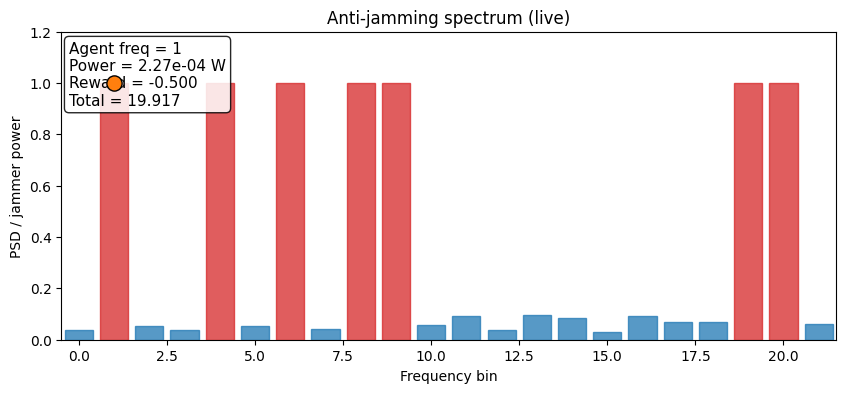

KeyboardInterrupt: 

In [11]:
import gymnasium as gym

num_episodes = 30
max_steps = 200
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action = greedy_policy(obs, base_env)
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}") if (ep+1) % 5 == 0 else None
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()


### instantiate env and agent (DQN) to learn for 200_000 steps

In [108]:
import gymnasium as gym
from gymnasium.wrappers import RecordEpisodeStatistics, TimeLimit

from stable_baselines3 import DQN
from stable_baselines3.common.vec_env import DummyVecEnv, VecMonitor
from stable_baselines3.common.callbacks import EvalCallback

def make_env():
    env = gym.make("AntiJammingEnv-v0", render_mode=None)
    env = RecordEpisodeStatistics(env)
    env = gym.wrappers.TimeLimit(env, max_episode_steps=200)

    return env

vec_env = DummyVecEnv([make_env])   #make one training env
vec_env = VecMonitor(vec_env)

eval_env = DummyVecEnv([make_env]) #make one eval env
eval_env = VecMonitor(eval_env)



model = DQN(
    policy="MlpPolicy",
    env=vec_env,
    learning_rate=5e-5,
    buffer_size=100_000,        # replay buffer size
    learning_starts=10_000,     # delay gradient updates until the buffer has this many samples
    batch_size=512,
    gamma=0.99,
    target_update_interval=1_000,
    train_freq=(4, "step"),
    exploration_fraction=0.2,
    exploration_initial_eps=1.0,
    exploration_final_eps=0.05,
    verbose=1,
    tensorboard_log="runs/anti_jam_dqn",
    device="auto",
)

eval_cb = EvalCallback(
    eval_env,
    eval_freq=5_000,
    n_eval_episodes=10,
    deterministic=True
)

model.learn(
    total_timesteps=200_000,
    log_interval=100,          # <= IMPORTANT
    callback=eval_cb
)


Using cpu device
Logging to runs/anti_jam_dqn/DQN_12
Eval num_timesteps=5000, episode_reward=44.67 +/- 15.91
Episode length: 200.00 +/- 0.00
----------------------------------
| eval/               |          |
|    mean_ep_length   | 200      |
|    mean_reward      | 44.7     |
| rollout/            |          |
|    exploration_rate | 0.881    |
| time/               |          |
|    total_timesteps  | 5000     |
----------------------------------
New best mean reward!
Eval num_timesteps=10000, episode_reward=50.10 +/- 12.92
Episode length: 200.00 +/- 0.00
----------------------------------
| eval/               |          |
|    mean_ep_length   | 200      |
|    mean_reward      | 50.1     |
| rollout/            |          |
|    exploration_rate | 0.763    |
| time/               |          |
|    total_timesteps  | 10000    |
----------------------------------
New best mean reward!
Eval num_timesteps=15000, episode_reward=65.95 +/- 23.73
Episode length: 200.00 +/- 0.00
-------

In [111]:
import gymnasium as gym

num_episodes = 30
max_steps = 200
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}") if (ep+1) % 5 == 0 else None
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()


Episode 5: return=93.09, steps=200
Episode 10: return=85.12, steps=200
Episode 15: return=68.16, steps=200
Episode 20: return=79.58, steps=200
Episode 25: return=70.20, steps=200
Episode 30: return=77.19, steps=200
Mean reward over episodes: 83.82


In [4]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecMonitor, VecNormalize
from gymnasium.wrappers import RecordEpisodeStatistics, TimeLimit
from stable_baselines3.common.callbacks import EvalCallback


def make_env():
    env = gym.make("AntiJammingEnv-v0", render_mode=None)
    env = RecordEpisodeStatistics(env)
    env = TimeLimit(env, max_episode_steps=200)   # should be paper’s K
    return env

train_env = DummyVecEnv([make_env])
train_env = VecMonitor(train_env)
# train_env = VecNormalize(train_env, norm_obs=True, norm_reward=True)

eval_env  = DummyVecEnv([make_env])
eval_env  = VecMonitor(eval_env)
# eval_env  = VecNormalize(eval_env, training=False)

model = PPO(
    "MlpPolicy",
    train_env,
    learning_rate=2e-4,
    # n_steps=5*15,          # 5 full episodes per rollout
    batch_size=512,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    # tensorboard_log="runs/anti_jam_ppo",
    verbose=1,
    device="auto",
    # ent_coef = 0.0001
)

eval_cb = EvalCallback(
    eval_env,
    eval_freq=5_000,
    n_eval_episodes=20,
    deterministic=True
)

model.learn(1_000_000, log_interval=100, callback=eval_cb)


Using cpu device
Eval num_timesteps=5000, episode_reward=63.77 +/- 23.70
Episode length: 200.00 +/- 0.00
------------------------------------------
| eval/                   |              |
|    mean_ep_length       | 200          |
|    mean_reward          | 63.8         |
| time/                   |              |
|    total_timesteps      | 5000         |
| train/                  |              |
|    approx_kl            | 0.0025912256 |
|    clip_fraction        | 0            |
|    clip_range           | 0.2          |
|    entropy_loss         | -7           |
|    explained_variance   | -0.0248      |
|    learning_rate        | 0.0002       |
|    loss                 | 2.48         |
|    n_updates            | 20           |
|    policy_gradient_loss | -0.0244      |
|    value_loss           | 6.66         |
------------------------------------------
New best mean reward!
Eval num_timesteps=10000, episode_reward=78.10 +/- 20.40
Episode length: 200.00 +/- 0.00
----------

In [37]:
import gymnasium as gym

num_episodes = 30
max_steps = 200
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action, _ = model.predict(obs, deterministic=False)  #no deterministic for PPO
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}") if (ep+1) % 5 == 0 else None
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()


Episode 5: return=144.96, steps=200
Episode 10: return=164.29, steps=200
Episode 15: return=102.85, steps=200
Episode 20: return=146.86, steps=200
Episode 25: return=142.30, steps=200
Episode 30: return=176.62, steps=200
Mean reward over episodes: 149.79


In [2]:
import torch
import gymnasium as gym

num_episodes = 30
max_steps    = 200
cum_return   = 0.0

env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)

for ep in range(num_episodes):
    obs, _ = env.reset()
    ep_return = 0.0

    for t in range(max_steps):
        # ── PPO action (stochastic) ─────────────────────────────────────
        action, _ = model.predict(obs, deterministic=False)
        obs, reward, terminated, truncated, _ = env.step(action)
        ep_return += reward

        # ── DEBUG probe every 25 env-steps ─────────────────────────────
        # if t % 1 == 0:
        with torch.no_grad():
            dist = model.policy.get_distribution(
                torch.as_tensor(obs).unsqueeze(0).to(model.device)
            )
            entropy    = dist.entropy().item()
            categorical = dist.distribution          # torch.distributions.Categorical
            probs = categorical.probs.squeeze(0).cpu().numpy()
            max_prob   = probs.max()
            arg_max    = probs.argmax()
            print(f"[ep {ep+1:02d} step {t:03d}] "
                f"entropy={entropy:.2f}  max-π={max_prob:.2f}  argmax={arg_max}")

        if terminated or truncated:
            break
    # ───────────────────────────────────────────────────────────────────
    if (ep + 1) % 5 == 0:
        print(f"Episode {ep+1}: return = {ep_return:.2f}, steps = {t+1}")

    cum_return += ep_return

env.close()
print(f"\nMean return over {num_episodes} episodes: {cum_return / num_episodes:.2f}")


NameError: name 'model' is not defined

In [99]:
# from stable_baselines3.common.evaluation import evaluate_policy

# mean_return, std_return = evaluate_policy(model, vec_env, n_eval_episodes=30, deterministic=True)
# print(f"DQN mean return: {mean_return:.1f} ± {std_return:.1f}")

In [ ]:
# from stable_baselines3.common.evaluation import evaluate_policy

# mean_return, std_return = evaluate_policy(model, vec_env, n_eval_episodes=30, deterministic=True)
# print(f"DQN mean return: {mean_return:.1f} ± {std_return:.1f}")

In [113]:

# env = gym.make("AntiJammingEnv-v0", render_mode="human")
# env = gym.wrappers.TimeLimit(env, max_episode_steps=20)


# # Reset environment to start a new episode
# observation, info = env.reset()
# # observation: what the agent can "see" - cart position, velocity, pole angle, etc.
# # info: extra debugging information (usually not needed for basic learning)

# print(f"Starting observation: {observation}")
# # Example output: [ 0.01234567 -0.00987654  0.02345678  0.01456789]
# # [cart_position, cart_velocity, pole_angle, pole_angular_velocity]

# episode_over = False
# total_reward = 0

# while not episode_over:
#     # Choose an action: 0 = push cart left, 1 = push cart right
#     action, _ = model.predict(observation, deterministic=True)  # greedy action

#     # Take the action and see what happens
#     observation, reward, terminated, truncated, info = env.step(int(action))
#     # reward: +1 for each step the pole stays upright
#     # terminated: True if pole falls too far (agent failed)
#     # truncated: True if we hit the time limit (500 steps)

#     total_reward += reward
#     episode_over = terminated or truncated

# print(f"Episode finished! Total reward: {total_reward}")
# env.close()
